<a href="https://colab.research.google.com/github/drewbenson-1/nfl-wr-coverage-separation-analysis/blob/main/NFL_WR_Sep_by_Coverage.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## NFL Wide Receiver Separation & Target Efficiency by Coverage Shell (2026)

In [5]:
from google.colab import files
import os

uploaded = files.upload()
print("\nUploaded files:", list(uploaded.keys()))
print("Files in current Colab folder:", os.listdir())

Saving rec_situation_2026_wr.csv to rec_situation_2026_wr.csv
Saving sep_coverage_2026_wr.csv to sep_coverage_2026_wr.csv

Uploaded files: ['rec_situation_2026_wr.csv', 'sep_coverage_2026_wr.csv']
Files in current Colab folder: ['.config', 'sep_coverage_2026_wr.csv', 'rec_situation_2026_wr.csv', 'sample_data']


In [13]:
import pandas as pd
import numpy as np

def load_fp_wide_csv(path: str) -> pd.DataFrame:
    raw = pd.read_csv(path)
    group_headers = raw.columns.tolist()
    metric_headers = raw.iloc[0].tolist()

    clean_cols = []
    for grp, met in zip(group_headers, metric_headers):
        grp_clean = (
            "" if str(grp).startswith("Unnamed")
            else str(grp).strip().lower().replace(" ", "_").replace("-", "_")
        )
        met_clean = (
            "" if pd.isna(met)
            else str(met).strip().lower().replace(" ", "_").replace("-", "_").replace("/", "_")
        )
        if met_clean == "player_id" or grp_clean == "player_id":
            clean_cols.append("player_id")
        elif grp_clean in ("", "player_details"):
            clean_cols.append(met_clean)
        else:
            clean_cols.append(f"{grp_clean}_{met_clean}")

    df = raw.iloc[2:].copy()
    df.columns = clean_cols
    df = df.reset_index(drop=True)
    df = df[df["player_id"].notna()].copy()

    # Preserve any text identifier column from conversion
    for col in df.columns:
        if not any(x in col for x in ["name", "team", "pos", "season", "player_id"]):
            df[col] = pd.to_numeric(df[col], errors="coerce")

    return df

sep_df = load_fp_wide_csv("sep_coverage_2026_wr.csv")
rec_df = load_fp_wide_csv("rec_situation_2026_wr.csv")
print(f"Loaded {len(sep_df)} players in sep_df, head player: {sep_df.iloc[0]['player_details.1_name']}")

Loaded 149 players in sep_df, head player: CeeDee Lamb


In [15]:
df = pd.merge(
    sep_df,
    rec_df,
    on="player_id",
    how="inner",
    suffixes=("_sep", "_rec"),
)

# Map columns dynamically
name_sep_col = "player_details.1_name_sep" if "player_details.1_name_sep" in df.columns else "name_sep"
name_rec_col = "player_details.1_name_rec" if "player_details.1_name_rec" in df.columns else "name_rec"

team_sep_col = "player_details.2_team_sep" if "player_details.2_team_sep" in df.columns else "team_sep"
team_rec_col = "player_details.2_team_rec" if "player_details.2_team_rec" in df.columns else "team_rec"

df["player"] = df[name_sep_col].fillna(df[name_rec_col])
df["team"] = df[team_sep_col].fillna(df[team_rec_col])

# Filter to >= 50 routes in BOTH Man and Zone coverage
qualified = df[(df["man_rte_sep"] >= 50) & (df["zone_rte_sep"] >= 50)].copy()

# Map exact columns found in debug output
qualified["sep_diff_man_zone"] = qualified["man.1_sep_score"] - qualified["zone.1_sep_score"]
qualified["yprr_diff_man_zone"] = qualified["man.2_yprr_rec"] - qualified["zone.2_yprr_rec"]

# Z-score gap: High Man Separation relative to Man TPRR
# (man.1_tprr does not get a suffix because it only exists in rec_df)
qualified["man_sep_z"] = (qualified["man.1_sep_score"] - qualified["man.1_sep_score"].mean()) / qualified["man.1_sep_score"].std(ddof=1)
qualified["man_tprr_z"] = (qualified["man.1_tprr"] - qualified["man.1_tprr"].mean()) / qualified["man.1_tprr"].std(ddof=1)
qualified["man_underutilized_gap"] = qualified["man_sep_z"] - qualified["man_tprr_z"]

# Z-score gap: High Zone Separation relative to Zone TPRR
# (zone.1_tprr does not get a suffix because it only exists in rec_df)
qualified["zone_sep_z"] = (qualified["zone.1_sep_score"] - qualified["zone.1_sep_score"].mean()) / qualified["zone.1_sep_score"].std(ddof=1)
qualified["zone_tprr_z"] = (qualified["zone.1_tprr"] - qualified["zone.1_tprr"].mean()) / qualified["zone.1_tprr"].std(ddof=1)
qualified["zone_underutilized_gap"] = qualified["zone_sep_z"] - qualified["zone_tprr_z"]

print(f"Qualified WRs (>=50 Man & >=50 Zone routes): {len(qualified)}")
qualified[["player", "team", "man_rte_sep", "man.1_sep_score", "zone_rte_sep", "zone.1_sep_score", "sep_diff_man_zone"]].sort_values("sep_diff_man_zone", ascending=False).head(10)

Qualified WRs (>=50 Man & >=50 Zone routes): 56


,player,team,man_rte_sep,man.1_sep_score,zone_rte_sep,zone.1_sep_score,sep_diff_man_zone
42,DeMario Douglas,NE,53,0.434,183,0.077,0.357
17,Garrett Wilson,NYJ,59,0.441,238,0.147,0.294
23,Jaxon Smith-Njigba,SEA,56,0.357,223,0.085,0.272
4,Ja'Marr Chase,CIN,60,0.333,270,0.070,0.263
72,Konata Mumpfield,LA,54,0.222,117,-0.034,0.256
30,Parker Washington,JAX,76,0.250,178,0.039,0.211
12,Matthew Golden,GB,64,0.250,249,0.040,0.210
38,Antonio Williams,WAS,71,0.254,177,0.062,0.192
61,Elic Ayomanor,TEN,63,0.270,141,0.085,0.185
28,Jerry Jeudy,CLV,66,0.242,201,0.070,0.172


In [18]:
print("=== TOP 10 MAN-OVER-ZONE SEPARATORS ===")
display(
    qualified.sort_values("sep_diff_man_zone", ascending=False)[
        ["player", "team", "man_rte_sep", "man.1_sep_score", "zone_rte_sep", "zone.1_sep_score", "sep_diff_man_zone", "man.2_yprr_rec"]
    ].head(10)
)

print("\n=== TOP 10 UNDERUTILIZED MAN SEPARATORS (High Separation vs. Low Man TPRR) ===")
display(
    qualified.sort_values("man_underutilized_gap", ascending=False)[
        ["player", "team", "man_rte_sep", "man.1_sep_score", "man.1_tprr", "man.2_yprr_rec", "man_underutilized_gap"]
    ].head(10)
)

# Save clean dataset to Colab and download if desired
qualified.to_csv("wr_coverage_separation_2026_clean.csv", index=False)
print("\nSaved wr_coverage_separation_2026_clean.csv successfully.")

=== TOP 10 MAN-OVER-ZONE SEPARATORS ===


,player,team,man_rte_sep,man.1_sep_score,zone_rte_sep,zone.1_sep_score,sep_diff_man_zone,man.2_yprr_rec
42,DeMario Douglas,NE,53,0.434,183,0.077,0.357,2.35
17,Garrett Wilson,NYJ,59,0.441,238,0.147,0.294,3.08
23,Jaxon Smith-Njigba,SEA,56,0.357,223,0.085,0.272,2.54
4,Ja'Marr Chase,CIN,60,0.333,270,0.070,0.263,2.07
72,Konata Mumpfield,LA,54,0.222,117,-0.034,0.256,3.46
30,Parker Washington,JAX,76,0.250,178,0.039,0.211,3.34
12,Matthew Golden,GB,64,0.250,249,0.040,0.210,3.80
38,Antonio Williams,WAS,71,0.254,177,0.062,0.192,2.33
61,Elic Ayomanor,TEN,63,0.270,141,0.085,0.185,0.58
28,Jerry Jeudy,CLV,66,0.242,201,0.070,0.172,0.32



=== TOP 10 UNDERUTILIZED MAN SEPARATORS (High Separation vs. Low Man TPRR) ===


,player,team,man_rte_sep,man.1_sep_score,man.1_tprr,man.2_yprr_rec,man_underutilized_gap
28,Jerry Jeudy,CLV,66,0.242,0.08,0.32,2.873869
4,Ja'Marr Chase,CIN,60,0.333,0.20,2.07,2.073232
38,Antonio Williams,WAS,71,0.254,0.16,2.33,1.947039
42,DeMario Douglas,NE,53,0.434,0.29,2.35,1.737271
17,Garrett Wilson,NYJ,59,0.441,0.31,3.08,1.537871
32,Rashod Bateman,BLT,69,0.188,0.16,1.60,1.413967
61,Elic Ayomanor,TEN,63,0.270,0.23,0.58,1.180484
24,Malachi Fields,NYG,68,0.044,0.09,0.51,1.146686
69,Treylon Burks,WAS,54,0.074,0.11,1.37,1.133053
25,Laquon Treadwell,IND,60,0.000,0.07,0.08,1.047243



Saved wr_coverage_separation_2026_clean.csv successfully.


## Main Takeaway

Main Takeaway (2026 NFL WRs — $\ge 50$ Man & $\ge 50$ Zone Routes, $n = 56$):
Across qualified wide receivers, average Man separation score ($0.113$) runs higher than average Zone separation score ($0.064$, mean differential $+0.049$). DeMario Douglas ($+0.357$), Garrett Wilson ($+0.294$), Jaxon Smith-Njigba ($+0.272$), and Ja'Marr Chase ($+0.263$) post the largest Man-over-Zone separation advantages—and Wilson, Smith-Njigba, and Douglas all pair strong Man separation with high Man YPRR ($2.35\text{–}3.08$). Meanwhile, receivers like Jerry Jeudy, Ja'Marr Chase, Antonio Williams, and Rashod Bateman rank near the top of man_underutilized_gap because their Man separation stands out relative to their Man target rate (TPRR), highlighting players whose coverage wins exceed their current man-coverage target share.

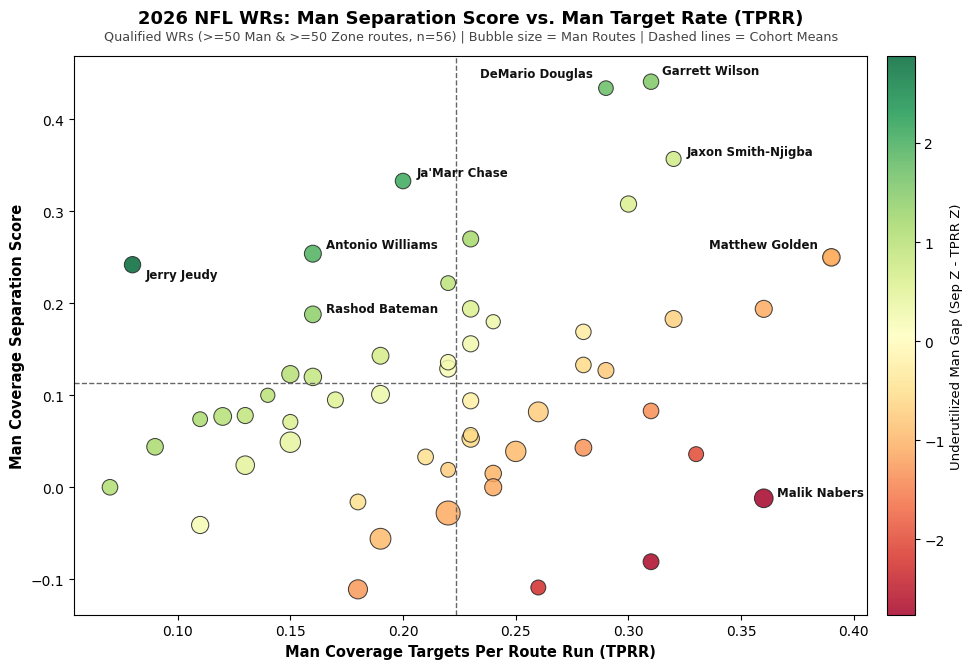

In [19]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10.5, 6.8))

x_mean = qualified["man.1_tprr"].mean()
y_mean = qualified["man.1_sep_score"].mean()

scatter = ax.scatter(
    qualified["man.1_tprr"],
    qualified["man.1_sep_score"],
    s=qualified["man_rte_sep"] * 2.1,
    c=qualified["man_underutilized_gap"],
    cmap="RdYlGn",
    alpha=0.84,
    edgecolors="#222222",
    linewidth=0.75,
)

ax.axvline(x_mean, color="#666666", linestyle="--", linewidth=1)
ax.axhline(y_mean, color="#666666", linestyle="--", linewidth=1)

label_offsets = {
    "Garrett Wilson": (0.005, 0.008, "left"),
    "DeMario Douglas": (-0.006, 0.012, "right"),
    "Jaxon Smith-Njigba": (0.006, 0.004, "left"),
    "Ja'Marr Chase": (0.006, 0.006, "left"),
    "Jerry Jeudy": (0.006, -0.014, "left"),
    "Antonio Williams": (0.006, 0.006, "left"),
    "Rashod Bateman": (0.006, 0.003, "left"),
    "Malik Nabers": (0.006, 0.003, "left"),
    "Matthew Golden": (-0.006, 0.010, "right"),
}

for _, row in qualified.iterrows():
    if row["player"] in label_offsets:
        dx, dy, ha = label_offsets[row["player"]]
        ax.annotate(
            row["player"],
            (row["man.1_tprr"], row["man.1_sep_score"]),
            xytext=(row["man.1_tprr"] + dx, row["man.1_sep_score"] + dy),
            ha=ha,
            fontsize=8.5,
            fontweight="bold",
            color="#111111",
        )

cbar = plt.colorbar(scatter, ax=ax, pad=0.02)
cbar.set_label("Underutilized Man Gap (Sep Z - TPRR Z)", fontsize=9.5)

ax.set_title("2026 NFL WRs: Man Separation Score vs. Man Target Rate (TPRR)", fontsize=13, fontweight="bold", pad=24)
ax.text(
    0.5, 1.03,
    "Qualified WRs (>=50 Man & >=50 Zone routes, n=56) | Bubble size = Man Routes | Dashed lines = Cohort Means",
    transform=ax.transAxes, ha="center", fontsize=9.2, color="#444444"
)
ax.set_xlabel("Man Coverage Targets Per Route Run (TPRR)", fontsize=10.5, fontweight="bold")
ax.set_ylabel("Man Coverage Separation Score", fontsize=10.5, fontweight="bold")

plt.tight_layout()
plt.savefig("wr_man_sep_vs_tprr.png", dpi=200, bbox_inches="tight")
plt.show()